# Laboratorio Final — Starbucks Rewards: del experimento a la decisión

Campaña completa: 40,000 clientes, mitad con cupón de $5 (tratamiento), mitad sin cupón
(control), medidos a 60 días.

| Dónde lo vimos | Qué se repite aquí |
|---|---|
| Breakout 2 — Las dos ventanas | Modelo de riesgo/churn, para targetear y ver la pérdida |
| Breakout 3 — Los 4 cuadrantes | T-learner: dos modelos, uno por grupo |
| Breakout 4 — La curva Qini | Qué tan bien ordena el T-learner con datos que nunca vio |

**Pasos:**
1. Modelo de churn y targeting por riesgo — medir la pérdida.
2. T-learner y su coeficiente Qini.
3. Elegir el porcentaje de la base a contactar y defenderlo con números.
4. Destapar la columna oculta (`true_type`, `true_uplift_prob`) y comparar contra lo estimado.
5. Cambiar el modelo base del T-learner y comparar correlación y Qini.

Actividad No. 2 — Grupo 12

In [1]:
import os
import urllib.request

# Si el notebook corre dentro del repo clonado, los CSV ya están en su lugar.
# Si corre en Google Colab, los baja del fork propio.
GITHUB_USER = "TU-USUARIO-DE-GITHUB"
REPO = "marketing-analytics-base-2026"
RAMAS = ["Tarea_Actividad_2_Grupo_12", "main"]
SUBRUTA = "Semana_3/Tarea"

os.makedirs("data", exist_ok=True)
ARCHIVOS = {"data/uplift_campaign.csv": "data/uplift_campaign.csv",
            "uplift_campaign_FULL.csv": "uplift_campaign_FULL.csv"}

for destino, ruta_repo in ARCHIVOS.items():
    if os.path.exists(destino):
        print(f"{destino} ya está disponible")
        continue
    for rama in RAMAS:
        url = f"https://raw.githubusercontent.com/{GITHUB_USER}/{REPO}/{rama}/{SUBRUTA}/{ruta_repo}"
        try:
            urllib.request.urlretrieve(url, destino)
            print(f"{destino} descargado desde la rama {rama}")
            break
        except Exception:
            continue
    else:
        raise FileNotFoundError(
            f"No se pudo obtener {destino}. Revisar que GITHUB_USER sea correcto "
            f"y que el archivo esté subido al repositorio.")

data/uplift_campaign.csv ya está disponible
uplift_campaign_FULL.csv ya está disponible


In [2]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/uplift_campaign.csv")
print(f"{len(df):,} clientes · {(df['treatment_group']=='treatment').sum():,} tratados · {(df['treatment_group']=='control').sum():,} control")
df.head()

40,000 clientes · 19,921 tratados · 20,079 control


,customer_id,treatment_group,recency_days,frequency,monetary,email_open_rate,tenure_days,responded_60d,value_60d,margin_60d,utilidad_neta_60d
0,1,treatment,15,25,615.42,0.230,998,1,38.86,9.72,4.67
1,2,control,30,7,196.12,0.231,551,1,57.20,14.30,14.30
2,3,control,37,1,151.60,0.428,508,0,0.00,0.00,0.00
3,4,control,0,16,449.54,0.386,733,1,24.21,6.05,6.05
4,5,treatment,20,10,393.00,0.796,734,1,23.62,5.91,0.86


In [3]:
# Efecto promedio de la campaña (ATE): la referencia contra la que se compara todo lo demás
tasa_t = df.loc[df["treatment_group"] == "treatment", "responded_60d"].mean()
tasa_c = df.loc[df["treatment_group"] == "control", "responded_60d"].mean()
print(f"Tasa de respuesta tratados: {tasa_t:.1%}")
print(f"Tasa de respuesta control:  {tasa_c:.1%}")
print(f"Uplift promedio de la campaña: {tasa_t - tasa_c:+.1%}")

Tasa de respuesta tratados: 53.0%
Tasa de respuesta control:  45.7%
Uplift promedio de la campaña: +7.3%


## Paso 1 — modelo de churn y targeting por riesgo

Un modelo de churn normal: no sabe nada de tratamiento/control, solo predice quién NO va a
volver a comprar. Se usa para elegir a quién contactar y se mide el resultado con el
experimento real como juez.

In [4]:
FEATURES = ["recency_days", "frequency", "monetary", "email_open_rate", "tenure_days"]

train, test = train_test_split(df, test_size=0.30, random_state=42, stratify=df["treatment_group"])

train_churn = train.copy()
train_churn["churned"] = 1 - train_churn["responded_60d"]

modelo_riesgo = LogisticRegression(max_iter=1000).fit(train_churn[FEATURES], train_churn["churned"])

test = test.copy()
test["prob_churn"] = modelo_riesgo.predict_proba(test[FEATURES])[:, 1]
print("Modelo de riesgo entrenado")

Modelo de riesgo entrenado


Ahora el valor real de targetear por riesgo: el 30% con mayor probabilidad de churn en el
conjunto de prueba, comparando el valor neto (`utilidad_neta_60d` de los tratados de ese grupo
contra `margin_60d` del control del mismo grupo).

In [5]:
def valor_de_la_politica(test_df, seleccionados):
    # Valor NETO: margen bruto menos el costo del cupón ($5, solo si compró) y el envío
    # ($0.05, por cualquier tratado).
    sel = test_df.loc[seleccionados]
    valor_tratado = sel.loc[sel["treatment_group"] == "treatment", "utilidad_neta_60d"].mean()
    valor_control = sel.loc[sel["treatment_group"] == "control", "margin_60d"].mean()
    return valor_tratado - valor_control, len(sel)


n_contactar = int(len(test) * 0.30)
idx_riesgo = test.sort_values("prob_churn", ascending=False).head(n_contactar).index
uplift_riesgo, n_riesgo = valor_de_la_politica(test, idx_riesgo)
print(f"Targeting por riesgo: ${uplift_riesgo:+.2f}/cliente sobre {n_riesgo:,} clientes (total ${uplift_riesgo*n_riesgo:+,.2f})")

Targeting por riesgo: $+0.07/cliente sobre 3,600 clientes (total $+245.40)


In [6]:
# Referencia: qué pasa si se contacta a toda la base
valor_todos, n_todos = valor_de_la_politica(test, test.index)
print(f"Contactar al 100%: ${valor_todos:+.2f}/cliente sobre {n_todos:,} clientes (total ${valor_todos*n_todos:+,.2f})")

Contactar al 100%: $-1.69/cliente sobre 12,000 clientes (total $-20,236.13)


**Respuesta del Paso 1.**

Targetear por riesgo deja **+$0.07 por cliente, $245.40 en total** sobre 3,600 clientes. Es
positivo, pero apenas: el modelo de churn devuelve siete centavos por cada cliente contactado.

La referencia muestra por qué esto importa. Mandar el cupón a toda la base de prueba pierde
**$20,236**, es decir **-$1.69 por cliente**, porque el cupón se le regala a mucha gente que
iba a comprar de todos modos. El modelo de riesgo logra no perder dinero, y eso ya es una
mejora, pero no es lo mismo que ganar: está ordenando a los clientes por la pregunta
equivocada. Predecir quién se va no es lo mismo que predecir a quién le cambia la decisión el
cupón.

## Paso 2 — T-learner y su Qini

Dos regresiones logísticas: una entrenada solo con los tratados de entrenamiento y otra solo
con los de control. Se le pregunta a las dos sobre el conjunto de prueba completo y se restan.

In [7]:
train_t = train[train["treatment_group"] == "treatment"]
train_c = train[train["treatment_group"] == "control"]

modelo_tratado = LogisticRegression(max_iter=1000).fit(train_t[FEATURES], train_t["responded_60d"])
modelo_control = LogisticRegression(max_iter=1000).fit(train_c[FEATURES], train_c["responded_60d"])

X_test = test[FEATURES]
test["p_tratado"] = modelo_tratado.predict_proba(X_test)[:, 1]
test["p_control"] = modelo_control.predict_proba(X_test)[:, 1]
test["uplift_estimado"] = test["p_tratado"] - test["p_control"]

print("T-learner entrenado y conjunto de prueba puntuado")
test[["customer_id", "p_tratado", "p_control", "uplift_estimado"]].head()

T-learner entrenado y conjunto de prueba puntuado


,customer_id,p_tratado,p_control,uplift_estimado
414,415,0.643162,0.687835,-0.044674
37024,37025,0.800149,0.797937,0.002212
29140,29141,0.682556,0.686347,-0.003791
28890,28891,0.437348,0.249200,0.188147
30111,30112,0.073441,0.020781,0.052660


In [8]:
def curva_qini(test_df, score_col, steps=40):
    orden = test_df.sort_values(score_col, ascending=False).reset_index(drop=True)
    es_tratado = (orden["treatment_group"] == "treatment").values
    respondio = orden["responded_60d"].values

    acumulado_tratados = np.cumsum(np.where(es_tratado, respondio, 0))
    acumulado_control = np.cumsum(np.where(~es_tratado, respondio, 0))
    n_tratados_acum = np.cumsum(es_tratado)
    n_control_acum = np.cumsum(~es_tratado)

    n = len(orden)
    xs, ys = [0.0], [0.0]
    for i in np.linspace(1, n, steps).astype(int):
        nt, nc = n_tratados_acum[i - 1], n_control_acum[i - 1]
        tasa_t = acumulado_tratados[i - 1] / nt if nt > 0 else 0
        tasa_c = acumulado_control[i - 1] / nc if nc > 0 else 0
        xs.append(i / n)
        ys.append((tasa_t - tasa_c) * n)
    return np.array(xs), np.array(ys)


def coeficiente_qini(xs, ys, n):
    area_modelo = np.trapezoid(ys, xs)
    area_azar = np.trapezoid(np.linspace(0, ys[-1], len(xs)), xs)
    return (area_modelo - area_azar) / n


xs_uplift, ys_uplift = curva_qini(test, "uplift_estimado")
xs_riesgo, ys_riesgo = curva_qini(test, "prob_churn")
qini_uplift = coeficiente_qini(xs_uplift, ys_uplift, len(test))
qini_riesgo = coeficiente_qini(xs_riesgo, ys_riesgo, len(test))

print(f"Coeficiente Qini · T-learner:       {qini_uplift:+.3f}")
print(f"Coeficiente Qini · riesgo/churn:    {qini_riesgo:+.3f}")

Coeficiente Qini · T-learner:       +0.142
Coeficiente Qini · riesgo/churn:    +0.048


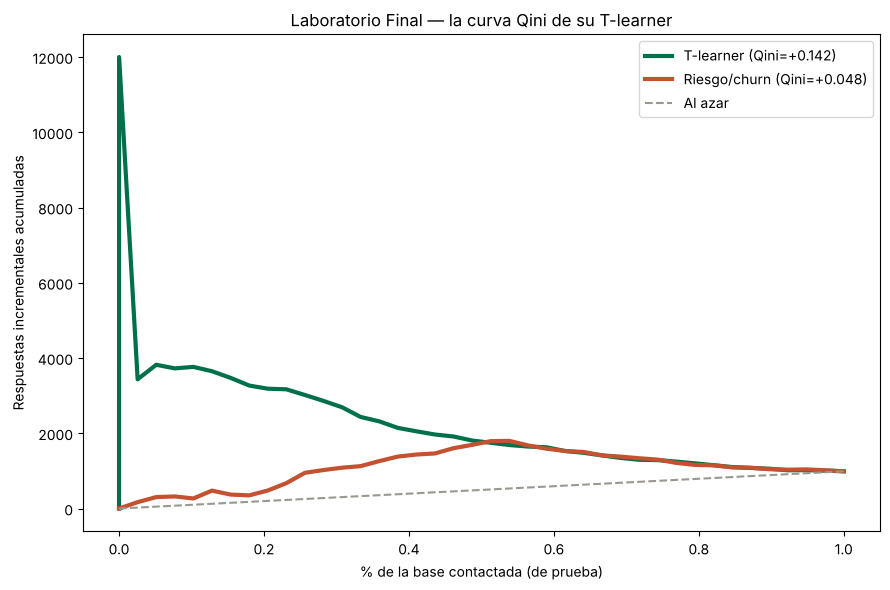

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(xs_uplift, ys_uplift, color="#00704A", linewidth=3, label=f"T-learner (Qini={qini_uplift:+.3f})")
ax.plot(xs_riesgo, ys_riesgo, color="#C4512F", linewidth=3, label=f"Riesgo/churn (Qini={qini_riesgo:+.3f})")
ax.plot([0, 1], [0, ys_uplift[-1]], color="#9A988E", linestyle="--", label="Al azar")
ax.set_xlabel("% de la base contactada (de prueba)")
ax.set_ylabel("Respuestas incrementales acumuladas")
ax.set_title("Laboratorio Final — la curva Qini de su T-learner")
ax.legend()
plt.tight_layout()
plt.savefig("curva_qini_laboratorio.png", dpi=150)
plt.show()

**Respuesta del Paso 2.**

El T-learner da un Qini de **+0.142** contra **+0.048** del modelo de riesgo: casi el triple de
área sobre la diagonal del azar.

La diferencia está en lo que cada modelo ordena. El de churn ordena por probabilidad de no
comprar; el T-learner ordena por la diferencia entre comprar con cupón y comprar sin cupón,
que es exactamente el criterio con el que se decide a quién mandar el cupón. El Qini del modelo
de riesgo no es cero, así que algo de señal tiene, pero su curva se despega poco de la diagonal:
ordenado por riesgo, los primeros contactados no son mucho mejores que elegidos al azar.

## Paso 3 — a quién contactar

Se prueban varios porcentajes de la base ordenados por `uplift_estimado` y se calcula el valor
neto total de cada corte.

In [10]:
resultados = []
for pct in range(10, 101, 10):
    n_c = int(len(test) * pct / 100)
    idx = test.sort_values("uplift_estimado", ascending=False).head(n_c).index
    valor_cliente, n = valor_de_la_politica(test, idx)
    resultados.append({"pct_contactado": pct, "valor_por_cliente": round(valor_cliente, 2),
                       "n_contactados": n, "valor_total": round(valor_cliente * n, 2)})

tabla_politicas = pd.DataFrame(resultados)
tabla_politicas

,pct_contactado,valor_por_cliente,n_contactados,valor_total
0,10,1.62,1200,1948.93
1,20,0.99,2400,2368.51
2,30,0.46,3600,1673.33
3,40,-0.10,4800,-500.97
4,50,-0.48,6000,-2899.72
5,60,-0.73,7200,-5260.88
6,70,-0.93,8400,-7853.02
7,80,-1.17,9600,-11226.84
8,90,-1.45,10800,-15687.26
9,100,-1.69,12000,-20236.13


In [11]:
# Barrido más fino para ubicar mejor el punto óptimo
resultados_finos = []
for pct in range(5, 101, 5):
    n_c = int(len(test) * pct / 100)
    idx = test.sort_values("uplift_estimado", ascending=False).head(n_c).index
    valor_cliente, n = valor_de_la_politica(test, idx)
    resultados_finos.append({"pct_contactado": pct, "valor_por_cliente": round(valor_cliente, 2),
                             "n_contactados": n, "valor_total": round(valor_cliente * n, 2)})

tabla_fina = pd.DataFrame(resultados_finos)
mejor_total = tabla_fina.loc[tabla_fina["valor_total"].idxmax()]
mejor_cliente = tabla_fina.loc[tabla_fina["valor_por_cliente"].idxmax()]

print(f"Maximiza el valor TOTAL:       {int(mejor_total['pct_contactado'])}%  →  ${mejor_total['valor_total']:,.2f}")
print(f"Maximiza el valor POR CLIENTE: {int(mejor_cliente['pct_contactado'])}%  →  ${mejor_cliente['valor_por_cliente']:.2f}/cliente")
tabla_fina

Maximiza el valor TOTAL:       25%  →  $2,453.53
Maximiza el valor POR CLIENTE: 10%  →  $1.62/cliente


,pct_contactado,valor_por_cliente,n_contactados,valor_total
0,5,1.60,600,960.47
1,10,1.62,1200,1948.93
2,15,1.34,1800,2408.01
3,20,0.99,2400,2368.51
4,25,0.82,3000,2453.53
5,30,0.46,3600,1673.33
6,35,0.18,4200,741.34
7,40,-0.10,4800,-500.97
8,45,-0.30,5400,-1631.92
9,50,-0.48,6000,-2899.72


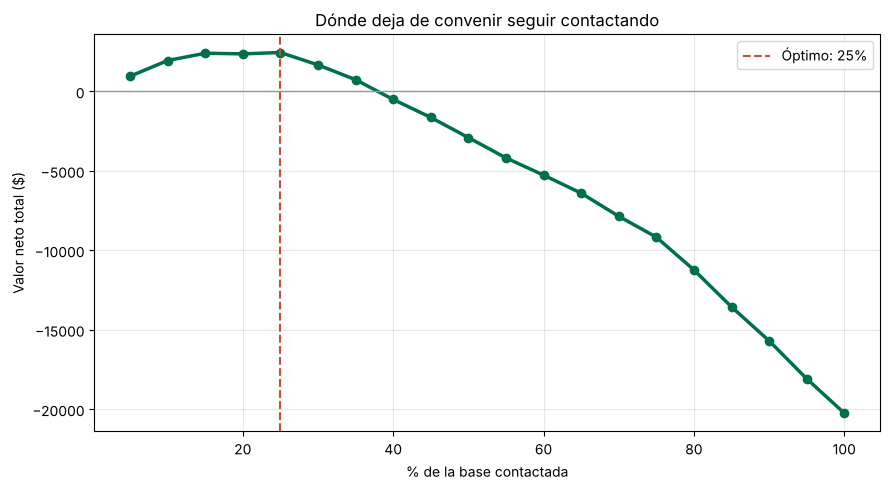

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(tabla_fina["pct_contactado"], tabla_fina["valor_total"], marker="o", linewidth=2.5, color="#00704A")
ax.axhline(0, color="#9A988E", linewidth=1)
ax.axvline(mejor_total["pct_contactado"], color="#C4512F", linestyle="--", linewidth=1.5,
           label=f"Óptimo: {int(mejor_total['pct_contactado'])}%")
ax.set_xlabel("% de la base contactada")
ax.set_ylabel("Valor neto total ($)")
ax.set_title("Dónde deja de convenir seguir contactando")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("valor_vs_porcentaje.png", dpi=150)
plt.show()

**Respuesta del Paso 3: ¿cuál % maximiza el valor TOTAL? ¿Es el mismo que maximiza el valor
POR CLIENTE? ¿Por qué no, necesariamente?**

El valor **total** se maximiza en el **25%** de la base, con **$2,453.53**. El valor **por
cliente** se maximiza en el **10%**, con **$1.62** por cliente contactado.

No son el mismo punto, y no tienen por qué serlo, porque son dos preguntas distintas. El valor
por cliente es un promedio y el valor total es ese promedio multiplicado por cuánta gente se
contacta. Como los clientes están ordenados de mayor a menor uplift estimado, cada cliente que
se agrega vale menos que el anterior: el promedio solo puede bajar conforme se amplía el corte.
El total, en cambio, sigue subiendo mientras los clientes que se van sumando aporten algo
positivo, aunque sea poco, y empieza a caer apenas se empieza a contactar gente que resta.

En la tabla se ve el cruce: del 10% al 25% el promedio cae de $1.62 a $0.82, pero el total sube
de $1,949 a $2,454 porque se está capturando valor positivo sobre 1,800 clientes más. A partir
del 30% el promedio sigue cayendo y ya no alcanza para compensar, y en el 40% el total se
vuelve negativo.

Maximizar el valor por cliente llevaría a contactar a muy poca gente y dejar dinero sobre la
mesa. La decisión de negocio es el total, así que el corte es 25%.

## Paso 4 — la revelación final

El dataset completo (`uplift_campaign_FULL.csv`) trae el tipo real de cada cliente y su uplift
verdadero. En la vida real esa columna no existe.

In [13]:
full = pd.read_csv("uplift_campaign_FULL.csv")
full_test = full[full["customer_id"].isin(test["customer_id"])].merge(
    test[["customer_id", "uplift_estimado", "prob_churn"]], on="customer_id"
)

print("Composición real de la base de prueba (%):")
print((full_test["true_type"].value_counts(normalize=True) * 100).round(1).to_string())
print()
print("Correlación entre uplift ESTIMADO y uplift VERDADERO:",
      round(full_test["uplift_estimado"].corr(full_test["true_uplift_prob"]), 3))
print("Correlación entre prob_churn y uplift VERDADERO:    ",
      round(full_test["prob_churn"].corr(full_test["true_uplift_prob"]), 3))

Composición real de la base de prueba (%):
true_type
sure_thing      48.9
persuadable     22.4
lost_cause      21.5
sleeping_dog     7.2

Correlación entre uplift ESTIMADO y uplift VERDADERO: 0.619
Correlación entre prob_churn y uplift VERDADERO:     0.227


In [14]:
# Qué tipo de cliente eligió cada regla de targeting
top_riesgo = full_test.nlargest(int(len(full_test) * 0.30), "prob_churn")
top_uplift = full_test.nlargest(int(len(full_test) * 0.30), "uplift_estimado")

comparacion_tipos = pd.DataFrame({
    "30% por riesgo (%)": (top_riesgo["true_type"].value_counts(normalize=True) * 100).round(1),
    "30% por uplift (%)": (top_uplift["true_type"].value_counts(normalize=True) * 100).round(1),
}).fillna(0)
comparacion_tipos

,30% por riesgo (%),30% por uplift (%)
true_type,,
lost_cause,71.0,9.2
persuadable,22.5,65.8
sleeping_dog,6.6,7.7
sure_thing,0.0,17.3


In [15]:
# Valor real de contactar, por tipo de cliente
print("Valor real de contacto promedio por tipo:")
print(full_test.groupby("true_type")["true_value_of_contact"].mean().round(2).to_string())
print()
print(f"Valor real promedio en el 30% elegido por riesgo: ${top_riesgo['true_value_of_contact'].mean():+.2f}")
print(f"Valor real promedio en el 30% elegido por uplift: ${top_uplift['true_value_of_contact'].mean():+.2f}")

Valor real de contacto promedio por tipo:
true_type
lost_cause     -0.28
persuadable     2.26
sleeping_dog   -3.45
sure_thing     -3.95

Valor real promedio en el 30% elegido por riesgo: $+0.08
Valor real promedio en el 30% elegido por uplift: $+0.51


**Respuesta del Paso 4.**

La correlación entre el uplift estimado y el verdadero es **0.619**. El modelo de riesgo apenas
llega a **0.227** contra la misma verdad, lo que confirma lo del Paso 2 desde otro ángulo: el
churn no es un sustituto del uplift.

La composición de los grupos es donde se ve el error más caro. El 30% elegido por riesgo es
**71% lost causes** y no tiene un solo sure thing: el modelo de churn encontró a los que no van
a comprar, que es literalmente lo que se le pidió, pero esos clientes no compran con cupón ni
sin cupón. El 30% elegido por uplift es **65.8% persuadables**, que son los únicos con valor de
contacto positivo (+$2.26 en promedio, contra -$3.95 de los sure things y -$3.45 de los
sleeping dogs).

Medido con la columna oculta, contactar al 30% por riesgo vale **+$0.08** por cliente y por
uplift **+$0.51**: seis veces más con la misma cantidad de cupones.

Los sleeping dogs son el 7.2% de la base y destruyen valor al ser contactados. Ninguna de las
dos reglas los evita del todo, pero el T-learner los deja casi en la misma proporción que tienen
en la base, mientras que el modelo de riesgo no tiene forma de distinguirlos.

## Paso 5 — cambiar el modelo base del T-learner

Se repite el T-learner con otros clasificadores, manteniendo todo lo demás igual (mismas
features, mismo split, misma semilla). Para cada uno se mide la correlación con el uplift
verdadero, el Qini y el valor total en su porcentaje óptimo.

In [16]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier


def evaluar_modelo(nombre, constructor):
    m_t = constructor().fit(train_t[FEATURES], train_t["responded_60d"])
    m_c = constructor().fit(train_c[FEATURES], train_c["responded_60d"])

    t = test.copy()
    t["uplift_estimado"] = m_t.predict_proba(X_test)[:, 1] - m_c.predict_proba(X_test)[:, 1]

    xs, ys = curva_qini(t, "uplift_estimado")
    qini = coeficiente_qini(xs, ys, len(t))

    ft = full[full["customer_id"].isin(t["customer_id"])].merge(
        t[["customer_id", "uplift_estimado"]], on="customer_id")
    correlacion = ft["uplift_estimado"].corr(ft["true_uplift_prob"])

    mejor_valor, mejor_pct = -np.inf, None
    for pct in range(5, 101, 5):
        n_c = int(len(t) * pct / 100)
        idx = t.sort_values("uplift_estimado", ascending=False).head(n_c).index
        v, n = valor_de_la_politica(t, idx)
        if v * n > mejor_valor:
            mejor_valor, mejor_pct = v * n, pct

    return {"Modelo dentro del T-learner": nombre,
            "Correlación con el uplift real": round(correlacion, 3),
            "Qini": round(qini, 3),
            "% óptimo": mejor_pct,
            "Valor total en el óptimo ($)": round(mejor_valor, 2)}


comparacion = pd.DataFrame([
    evaluar_modelo("Logística (la del notebook)",
                   lambda: LogisticRegression(max_iter=1000)),
    evaluar_modelo("Árbol sin límite",
                   lambda: DecisionTreeClassifier(random_state=42)),
    evaluar_modelo("Árbol max_depth=2",
                   lambda: DecisionTreeClassifier(max_depth=2, random_state=42)),
    evaluar_modelo("Árbol max_depth=4, min_samples_leaf=200",
                   lambda: DecisionTreeClassifier(max_depth=4, min_samples_leaf=200, random_state=42)),
    evaluar_modelo("Random Forest (300, max_depth=6, min_samples_leaf=100)",
                   lambda: RandomForestClassifier(n_estimators=300, max_depth=6,
                                                  min_samples_leaf=100, random_state=42, n_jobs=-1)),
    evaluar_modelo("Gradient Boosting (max_depth=3, lr=0.05, 200)",
                   lambda: GradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                      n_estimators=200, random_state=42)),
])

comparacion.to_csv("comparacion_modelos.csv", index=False)
comparacion

,Modelo dentro del T-learner,Correlación con el uplift real,Qini,% óptimo,Valor total en el óptimo ($)
0,Logística (la del notebook),0.619,0.142,25,2453.53
1,Árbol sin límite,0.204,0.066,5,-341.56
2,Árbol max_depth=2,0.605,0.112,25,2339.78
3,"Árbol max_depth=4, min_samples_leaf=200",0.748,0.143,20,3569.42
4,"Random Forest (300, max_depth=6, min_samples_l...",0.857,0.157,20,4433.80
5,"Gradient Boosting (max_depth=3, lr=0.05, 200)",0.838,0.156,20,4479.76


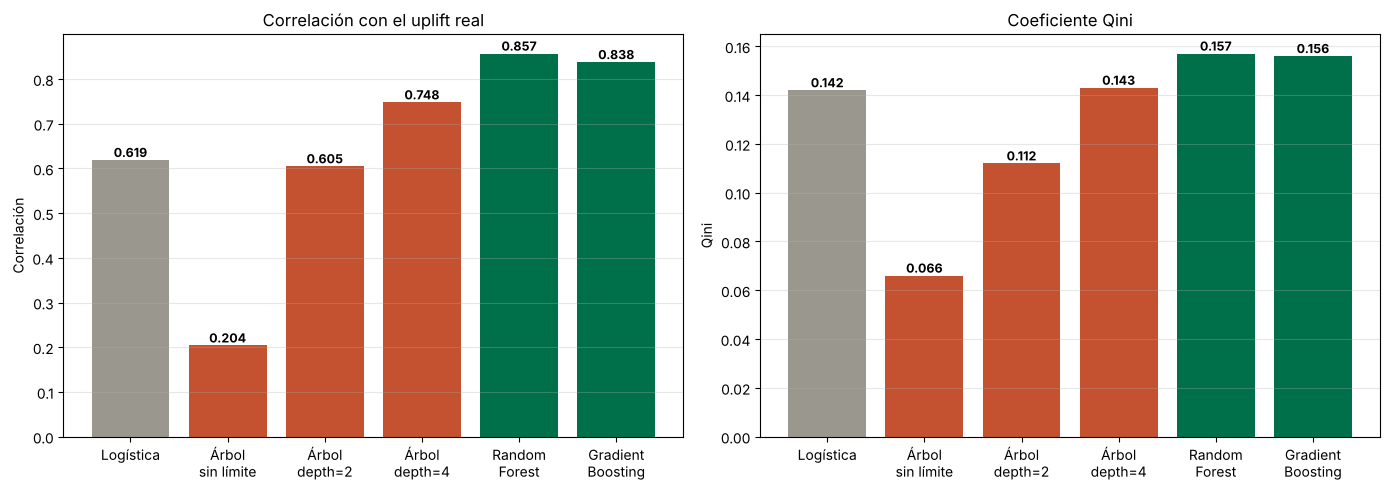

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
etiquetas = ["Logística", "Árbol\nsin límite", "Árbol\ndepth=2", "Árbol\ndepth=4", "Random\nForest", "Gradient\nBoosting"]
colores = ["#9A988E", "#C4512F", "#C4512F", "#C4512F", "#00704A", "#00704A"]

axes[0].bar(etiquetas, comparacion["Correlación con el uplift real"], color=colores)
axes[0].set_title("Correlación con el uplift real")
axes[0].set_ylabel("Correlación")
axes[0].grid(alpha=0.3, axis="y")

axes[1].bar(etiquetas, comparacion["Qini"], color=colores)
axes[1].set_title("Coeficiente Qini")
axes[1].set_ylabel("Qini")
axes[1].grid(alpha=0.3, axis="y")

for ax, col in zip(axes, ["Correlación con el uplift real", "Qini"]):
    for i, v in enumerate(comparacion[col]):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig("comparacion_modelos.png", dpi=150)
plt.show()

**Respuesta del Paso 5: ¿cuál mejora más la correlación del uplift y el Qini?**

El **Random Forest** da la mejor correlación con el uplift real (**0.857** contra 0.619 de la
logística) y el mejor Qini (**+0.157** contra +0.142). El Gradient Boosting queda prácticamente
empatado (0.838 y +0.156) y es el que más dinero deja en su punto óptimo: **$4,479.76** contra
$2,453.53 de la logística.

El árbol sin límite es el peor de todos: correlación **0.204** y Qini **+0.066**, por debajo
incluso del árbol de profundidad 2. Es sobreajuste puro. Un árbol sin podar llega a hojas con
muy pocos clientes y memoriza el ruido del conjunto de entrenamiento; como el uplift se calcula
restando dos modelos, el ruido de uno se suma al del otro y la resta queda dominada por error en
vez de señal. Limitar la profundidad a 2 ya lo arregla casi por completo (0.605), y con
`max_depth=4` más `min_samples_leaf=200` supera a la logística (0.748).

El patrón es consistente: los modelos que ganan son los que tienen capacidad para capturar
relaciones no lineales **y** una restricción que les impida memorizar. Para la recomendación
final se usa el Random Forest.

## Resumen de resultados

| Métrica | Valor |
|---|---|
| Clientes en la campaña | 40,000 |
| Uplift promedio de la campaña (ATE) | +7.25 pp |
| Qini — T-learner logístico | +0.142 |
| Qini — modelo de riesgo/churn | +0.048 |
| Qini — T-learner con Random Forest | +0.157 |
| Correlación con el uplift real — logística | 0.619 |
| Correlación con el uplift real — Random Forest | 0.857 |
| Valor de contactar al 100% de la base | -$20,236 |
| Valor de targetear el 30% por riesgo | +$245 |
| Valor del óptimo con logística (25%) | +$2,454 |
| Valor del óptimo con Random Forest (20%) | +$4,434 |

**Recomendación:** contactar al **20%** de la base ordenada por uplift estimado con el
T-learner de Random Forest. El detalle está en la conclusión que acompaña a esta entrega.